# Wind turbine SCADA audit: La Haute Borne

Two years (2014-2015) of 10-minute SCADA data from four Senvion MM82 turbines (2,050 kW, 80 m hub, 82 m rotor) in France, published by ENGIE.

The questions, in order:
1. Can the raw file be trusted? What's wrong with it, and can I prove the cleaned version is right?
2. What time is it, really? Is the clock correct?
3. Why do points fall off the power curve, and how much energy did each cause cost?
4. Does air density explain why the same wind gives different power?

The functions live in `../src/scada.py`, with tests in `../tests/`. This notebook tells the story.

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "..")
from src import scada

DATA = "../data/la_haute_borne"
FIG = "figures"
os.makedirs(FIG, exist_ok=True)
if not os.path.exists(os.path.join(DATA, scada.SCADA_FILE)):
    scada.download(DATA)               # about 36 MB, only the first time

pd.set_option("display.width", 140)

# Chart style: quiet axes, one ink color for text
INK, INK2, SURFACE, GRID = "#0b0b0b", "#52514e", "#fcfcfb", "#e4e3df"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
NORMAL = "#b9b8b3"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False,
})

## 1. The raw file

One row per turbine per 10 minutes. Every column is a 10-minute average, so anything shorter (a gust, a 2-minute stop) is smoothed in.

In [2]:
raw = pd.read_csv(os.path.join(DATA, scada.SCADA_FILE))
print(raw.shape)
print("expected rows: 4 turbines x 144 per day x 730 days =", 4 * 144 * 730)
raw.head()

(420480, 9)
expected rows: 4 turbines x 144 per day x 730 days = 420480


,Wind_turbine_name,Date_time,Ba_avg,P_avg,Ws_avg,Va_avg,Ot_avg,Ya_avg,Wa_avg
0,R80736,2014-01-01T01:00:00+01:00,-1.00,642.78003,7.12,0.66,4.69,181.34000,182.00999
1,R80721,2014-01-01T01:00:00+01:00,-1.01,441.06000,6.39,-2.48,4.94,179.82001,177.36000
2,R80790,2014-01-01T01:00:00+01:00,-0.96,658.53003,7.11,1.07,4.55,172.39000,173.50999
3,R80711,2014-01-01T01:00:00+01:00,-0.93,514.23999,6.87,6.95,4.30,172.77000,179.72000
4,R80790,2014-01-01T01:10:00+01:00,-0.96,640.23999,7.01,-1.90,4.68,172.39000,170.46001


The row count matches exactly, so the file *looks* complete. The time column says otherwise. The file stamps each row with a French offset: `+01:00` in winter, `+02:00` in summer.

**The night clocks went forward (30 Mar 2014):** 03:00-03:50 appears twice, with different readings. That's 12 rows where there should be 6.

In [3]:
one = raw[raw["Wind_turbine_name"] == "R80711"]
print("duplicated stamps for one turbine:", one["Date_time"].duplicated().sum())
one[one["Date_time"].str.startswith("2014-03-30T03")].sort_values("Date_time")[["Date_time", "P_avg", "Ws_avg"]]

duplicated stamps for one turbine: 12


,Date_time,P_avg,Ws_avg
50712,2014-03-30T03:00:00+02:00,202.320010,5.60
50719,2014-03-30T03:00:00+02:00,172.610000,5.30
50725,2014-03-30T03:10:00+02:00,138.080000,5.40
50726,2014-03-30T03:10:00+02:00,207.420000,5.49
50732,2014-03-30T03:20:00+02:00,119.900000,5.34
50733,2014-03-30T03:20:00+02:00,247.429990,5.52
50739,2014-03-30T03:30:00+02:00,33.669998,4.17
50741,2014-03-30T03:30:00+02:00,259.399990,5.60
50746,2014-03-30T03:40:00+02:00,51.220001,4.46
50747,2014-03-30T03:40:00+02:00,241.950000,5.48


**The night clocks went back (26 Oct 2014):** 02:00-02:50 happened twice in real life (once at `+02:00`, once at `+01:00`), but the file has it only once. An hour is missing.

Six extra rows in spring, six missing in autumn: they cancel out, which is why the row count still looked perfect.

In [4]:
night = one[one["Date_time"].str.startswith("2014-10-26T0")].sort_values("Date_time").copy()
night["utc (trusting offset)"] = pd.to_datetime(night["Date_time"], utc=True)
night[["Date_time", "utc (trusting offset)"]].iloc[8:16]

,Date_time,utc (trusting offset)
171657,2014-10-26T01:20:00+02:00,2014-10-25 23:20:00+00:00
171662,2014-10-26T01:30:00+02:00,2014-10-25 23:30:00+00:00
171664,2014-10-26T01:40:00+02:00,2014-10-25 23:40:00+00:00
171670,2014-10-26T01:50:00+02:00,2014-10-25 23:50:00+00:00
171674,2014-10-26T02:00:00+01:00,2014-10-26 01:00:00+00:00
171676,2014-10-26T02:10:00+01:00,2014-10-26 01:10:00+00:00
171681,2014-10-26T02:20:00+01:00,2014-10-26 01:20:00+00:00
171685,2014-10-26T02:30:00+01:00,2014-10-26 01:30:00+00:00


**Values that can't be real.** `isna()` only catches blanks. The rest needs a physical-sense check.

In [5]:
print("blank cells per column:")
print(raw.isna().sum().to_string())
raw[["P_avg", "Ws_avg", "Ba_avg", "Ot_avg"]].describe().T[["min", "max"]]

blank cells per column:
Wind_turbine_name       0
Date_time               0
Ba_avg               2569
P_avg                2569
Ws_avg               2569
Va_avg               2569
Ot_avg               2569
Ya_avg               2569
Wa_avg               2569


,min,max
P_avg,-17.92000,2051.870100
Ws_avg,0.00000,19.309999
Ba_avg,-121.26000,262.609990
Ot_avg,-273.20001,39.889999


- **Temperature at -273.2 °C** is absolute zero: a sentinel the logger writes when the sensor fails.
- **Pitch from -121° to 263°.** Blade pitch runs from about -2° to 92°, so a few rows are sensor errors.
- **Power down to -18 kW** is real: an idle turbine draws power for heaters and controls.
- **2,569 blank cells in every column** means whole rows are blank (logger down), not single sensors.

Pitch is the most useful column in the file. It says what the turbine was *trying* to do:

In [6]:
raw["Ba_avg"].round().value_counts().head(6)

Ba_avg
-1.0     287636
 45.0     55457
 0.0      32691
 90.0     13233
 1.0       3398
 92.0      2561
Name: count, dtype: int64

| Pitch | Meaning |
|---|---|
| about -1° | running, blades facing the wind |
| 45° | idle, waiting for wind |
| 90-92° | stopped (feathered) |
| a few degrees, above rated wind | spilling extra wind to hold 2,050 kW |

## 2. What time is it, really?

The clock-change mess raises a bigger question: are the summer offsets right on *every* summer day?

**The test.** ERA5 and MERRA-2 are weather reanalyses, always in UTC, with no daylight saving. Farm wind and reanalysis wind rise and fall together, so I find the time shift that lines them up best. I compare 3 weeks before each clock change with 3 weeks after, so the season and weather are similar on both sides.

- If the SCADA clock is right, the best shift should stay the same.
- If summer is an hour off, it should jump by about an hour, in the same direction, at every change.

**Prediction, written before running:** if the offsets are wrong, the lag jumps by about +60 min going into summer and -60 min coming out.

In [7]:
era5 = scada.load_era5(os.path.join(DATA, "era5_wind_la_haute_borne.csv"))
merra = scada.load_merra2(os.path.join(DATA, "merra2_la_haute_borne.csv"))
print("ERA5 row spacing:", era5.index.to_series().diff().value_counts().head(2).to_dict())

df_offset = scada.load_tidy(os.path.join(DATA, scada.SCADA_FILE), clock="offset")
scada.clock_test(df_offset, era5["ws_100m"])

ERA5 row spacing: {Timedelta('0 days 01:00:00'): 187170, Timedelta('0 days 03:00:00'): 1}


[offset] blank: 2,569 | bad temp: 34 | bad pitch: 43 | duplicates: 96 | kept: 417,815


,clock change,lag before (min),lag after (min),jump
0,2014-03-30,60,130,70
1,2014-10-26,110,30,-80
2,2015-03-29,60,120,60
3,2015-10-25,90,50,-40


All four changes jump by roughly an hour, always in the predicted direction. ERA5 has no daylight saving, so the jump comes from the SCADA.

There's a second clue: even in winter the lag isn't near 0. One explanation fits both clues: **the logger recorded UTC, and the export stamped those times with Paris offsets.** If that's right, reading the clock time as UTC (ignoring the offset) should give lags near 0 in both seasons, with no jump.

In [8]:
df = scada.load_tidy(os.path.join(DATA, scada.SCADA_FILE), clock="wall")
scada.clock_test(df, era5["ws_100m"])

[wall] blank: 2,569 | bad temp: 34 | bad pitch: 43 | duplicates: 96 | kept: 417,815


,clock change,lag before (min),lag after (min),jump
0,2014-03-30,0,10,10
1,2014-10-26,-10,-30,-20
2,2015-03-29,0,0,0
3,2015-10-25,-30,-10,20


No jump, and lags within half an hour of 0. A second, independent reanalysis (MERRA-2 at 50 m) should tell the same story:

In [9]:
merra_ws = merra["ws_50m"]
pd.concat({"MERRA-2, trusting offsets": scada.clock_test(df_offset, merra_ws).set_index("clock change"),
           "MERRA-2, clock read as UTC": scada.clock_test(df, merra_ws).set_index("clock change")}, axis=1)

MERRA-2, trusting offsets                      MERRA-2, clock read as UTC                     
                      lag before (min) lag after (min) jump           lag before (min) lag after (min) jump
clock change                                                                                               
2014-03-30                          40             130   90                        -20               0   20
2014-10-26                         150              30 -120                         30             -30  -60
2015-03-29                          20              90   70                        -40             -30   10
2015-10-25                         100              70  -30                        -20              20   40

MERRA-2 is coarser (hourly averages, a roughly 50 km grid, 50 m height), so it's noisier, but it agrees: trusting the offsets, the lag jumps the same way at all four changes. With the clock read as UTC, the jumps have no consistent direction, although one (Oct 2014) is still 60 minutes.

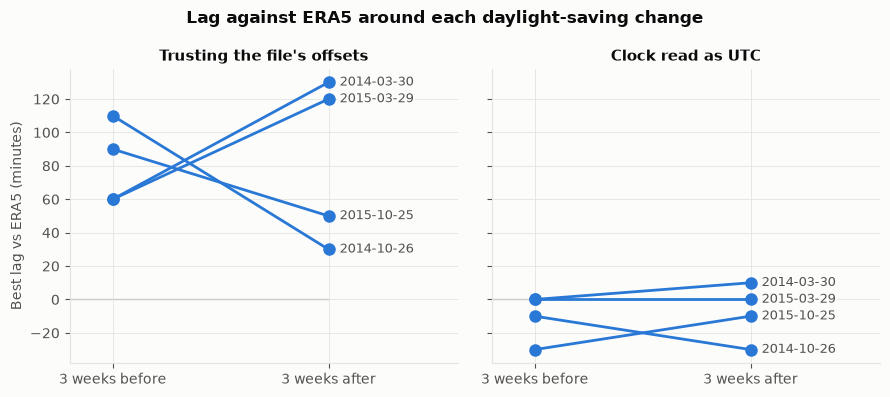

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharey=True)
for ax, (title, data) in zip(axes, [("Trusting the file's offsets", df_offset),
                                     ("Clock read as UTC", df)]):
    res = scada.clock_test(data, era5["ws_100m"])
    for _, r in res.iterrows():
        ax.plot([0, 1], [r["lag before (min)"], r["lag after (min)"]], color=BLUE, lw=2, marker="o", ms=8)
        ax.annotate(r["clock change"], (1, r["lag after (min)"]), xytext=(8, 0),
                    textcoords="offset points", va="center", fontsize=9, color=INK2,
                    bbox=dict(boxstyle="square,pad=0.1", fc=SURFACE, ec="none"), zorder=5)
    ax.set_xticks([0, 1], ["3 weeks before", "3 weeks after"])
    ax.set_xlim(-0.2, 1.6)
    ax.plot([-0.2, 1], [0, 0], color=INK2, lw=0.8, zorder=1)
    ax.set_title(title)
axes[0].set_ylabel("Best lag vs ERA5 (minutes)")
fig.suptitle("Lag against ERA5 around each daylight-saving change", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(f"{FIG}/clock_test.png", dpi=150)
plt.show()

**Conclusion.** The logger ran on UTC and the export used Paris offsets. Read with those offsets, every winter row lands an hour early in UTC and every summer row two hours early. This is strong evidence, not proof: only the logger's documentation could confirm it. From here on, I read the clock time as UTC.

This doesn't change anything that compares a turbine with itself. It matters as soon as SCADA is joined to anything else: weather, forecasts, prices.

## 3. Clean, then prove it's clean

`load_tidy` drops blank rows and duplicated stamps (both copies), and turns impossible temperature and pitch readings into NaN while keeping the row. `check` then counts failures for uniqueness, validity, the 10-minute grid, and completeness.

A check you've only seen pass proves nothing, so run it on the raw data first:

In [11]:
r = raw.rename(columns=scada.NAMES)
r["time"] = scada.parse_time(r["Date_time"], "wall")
scada.check(r)

,failures,status,% complete
duplicate turbine+time,48,FAIL,NaN
power_kw outside -50 to 2100,0,pass,NaN
ws outside 0 to 40,0,pass,NaN
pitch outside -5 to 95,43,FAIL,NaN
temp_c outside -40 to 50,34,FAIL,NaN
wdir outside 0 to 360,0,pass,NaN
off the 10-min grid,0,pass,NaN
R80711 missing slots,12,pass,99.99
R80721 missing slots,12,pass,99.99
R80736 missing slots,12,pass,99.99


In [12]:
scada.check(df)

,failures,status,% complete
duplicate turbine+time,0,pass,NaN
power_kw outside -50 to 2100,0,pass,NaN
ws outside 0 to 40,0,pass,NaN
pitch outside -5 to 95,0,pass,NaN
temp_c outside -40 to 50,0,pass,NaN
wdir outside 0 to 360,0,pass,NaN
off the 10-min grid,0,pass,NaN
R80711 missing slots,499,pass,99.53
R80721 missing slots,1233,pass,98.83
R80736 missing slots,459,pass,99.56


Every check passes on the cleaned data. Completeness can't be 100% once rows are removed, so it passes at 98% or more per turbine. R80721 is lowest because it had the most blank rows.

## 4. Why do points fall off the power curve?

Every 10-minute row gets one label. The rules use the turbine's specs and each turbine's own learned behavior, not numbers read off this farm, so the same code can run elsewhere by changing `SPEC`:

| # | Label | Rule (first match wins) |
|---|---|---|
| 1 | unknown | a key reading is missing |
| 2 | no usable wind | below cut-in + 1 m/s, or above cut-out |
| 3 | stopped | power ≤ 1% of rated, pitch > 20° from running pitch |
| 4 | transition | next to a stopped interval (a start or stop inside the 10 minutes) |
| 5 | derated | below the curve, pitched > 3° while below rated, 3+ intervals in a row |
| 6 | underperforming | below the curve by 3 spreads, pitch at running position |
| 7 | wind sensor suspect | **above** the curve by 3 spreads |
| 8 | normal | everything else |

"The curve" is each turbine's median power per 0.5 m/s bin, and "spread" is the scaled median absolute deviation, so the bad points don't bend it.

The core idea of rule 5: below rated wind, a healthy turbine keeps its blades at running pitch to catch everything it can. Pitching while the wind is below rated means something is holding it back.

In [13]:
curve = scada.reference_curve(df)
lab = scada.label_points(df, curve)
pd.crosstab(lab["label"], lab["turbine"], margins=True)

turbine,R80711,R80721,R80736,R80790,All
label,,,,,
derated,0,21,0,0,21
no usable wind,27923,33829,33994,32332,128078
normal,74697,68353,69051,70059,282160
stopped,815,573,554,1287,3229
transition,681,822,701,648,2852
underperforming,156,107,110,118,491
unknown,6,4,29,4,43
wind sensor suspect,343,178,222,198,941
All,104621,103887,104661,104646,417815


**Test the rules on cases I already know.** If a rule gets these wrong, it's broken, whatever the totals say.

**Case 1: 14 Sep 2015, R80711 stops at 15 m/s.** The 10:50 row averages running and stopped (about half power, pitch 23°). The restart at 11:10 is also caught.

In [14]:
lab[(lab["turbine"] == "R80711") & (lab["time"] >= "2015-09-14 10:30")
    & (lab["time"] <= "2015-09-14 11:20")][["time", "ws", "power_kw", "pitch", "label"]]

,time,ws,power_kw,pitch,label
88989,2015-09-14 10:30:00+00:00,10.92,1563.56010,0.64,normal
88990,2015-09-14 10:40:00+00:00,8.70,981.84003,-0.97,normal
88991,2015-09-14 10:50:00+00:00,14.85,924.29999,23.17,transition
88992,2015-09-14 11:00:00+00:00,14.94,-3.48000,90.00,stopped
88993,2015-09-14 11:10:00+00:00,10.02,897.83002,11.52,transition
88994,2015-09-14 11:20:00+00:00,8.30,868.96997,-0.99,normal


**Case 2: 2 Jan 2015, an ice stop and then a derate.** Below freezing overnight, three turbines stopped, and their anemometers read 2-4 m/s while R80711 next door read 5-12. A stopped rotor doesn't slow the air, so a stopped turbine should read *more*, not less: the anemometers were probably iced. After the thaw, R80721 came back capped near 1,160 kW with pitch at 5-8°, while its neighbors ran near 0°.

In [15]:
jan2 = lab[(lab["time"] >= "2015-01-02 00:00") & (lab["time"] < "2015-01-02 15:00")]
jan2.pivot_table(index=jan2["time"].dt.floor("h"), columns="turbine",
                 values=["power_kw", "ws", "pitch"]).round(0).astype("Int64")

pitch                      power_kw                          ws                     
turbine                   R80711 R80721 R80736 R80790   R80711 R80721 R80736 R80790 R80711 R80721 R80736 R80790
time                                                                                                           
2015-01-02 00:00:00+00:00     -1     90     90     90      422     -4     -1     -3      5      2      2      2
2015-01-02 01:00:00+00:00     -1     90     90     90      823     -4     -1     -4      7      2      2      2
2015-01-02 02:00:00+00:00     -1     90     90     90     1121     -5     -1     -4      8      3      2      3
2015-01-02 03:00:00+00:00     -1     90     90     90     1213     -4     -1     -3      8      3      2      3
2015-01-02 04:00:00+00:00      0     90     90     90     1730     -4     -1     -3     10      3      3      4
2015-01-02 05:00:00+00:00      5     90     90     90     2044     -4     -1     -3     12      7      6      9
2015-01-02 06:00:00+00:00      4     90     90     90     2021     -4     -1     -3     12     11     10     10
2015-01-02 07:00:00+00:00      4     90     65     27     2024     -4    313   1215     12     11     10     11
2015-01-02 08:00:00+00:00      1     31      7      0     1841    808   1413   1769      9      8      8      9
2015-01-02 09:00:00+00:00      2      8      0      2     1916   1164   1793   1976     10      9     10     10
2015-01-02 10:00:00+00:00      2      7      0      2     1955   1166   1811   1980     12     11     11     12
2015-01-02 11:00:00+00:00      0      6     -1      1     1865   1164   1645   1863     11     11     11     11
2015-01-02 12:00:00+00:00      0      5      0      0     1713   1158   1754   1708     11     11     11     11
2015-01-02 13:00:00+00:00     -1     37     -1     -1     1328    647   1456   1369      9      9     10      9
2015-01-02 14:00:00+00:00     -1     44     -1     -1     1174    416   1137   1108      9      9      9      8

In [16]:
lab[(lab["turbine"] == "R80721") & (lab["time"] >= "2015-01-02 06:00")
    & (lab["time"] < "2015-01-02 14:00")]["label"].value_counts()

label
derated                21
stopped                15
wind sensor suspect     6
normal                  4
transition              2
Name: count, dtype: int64

In [17]:
# Energy R80721 lost during the derate, compared with R80790 running freely next to it
win = jan2[jan2["time"].between("2015-01-02 09:00", "2015-01-02 12:50")]
by = win.groupby("turbine")["power_kw"].sum() / 6
print(f"R80790 produced {by['R80790']:.0f} kWh, R80721 {by['R80721']:.0f} kWh "
      f"-> about {(by['R80790'] - by['R80721']) / 1000:.1f} MWh lost in 4 hours")

R80790 produced 7526 kWh, R80721 4652 kWh -> about 2.9 MWh lost in 4 hours


Pitch says this was a deliberate cap, not ice on the blades (iced blades would show low power with pitch near 0°). *Why* it was capped isn't in the data. There are no alarm codes, so "a cautious restart after icing" is a guess.

**Case 3: 23 Feb 2015, all four anemometers ice at once.** All four turbines read about 6 m/s while making far more power than 6 m/s can give. ERA5 says the wind held at about 11 m/s.

In [18]:
feb = lab[(lab["time"] >= "2015-02-23 03:00") & (lab["time"] < "2015-02-23 10:00")]
t = feb.pivot_table(index=feb["time"].dt.floor("h"), columns="turbine", values=["ws", "power_kw"]).round(0)
t[("ERA5", "ws_100m")] = era5["ws_100m"].reindex(t.index).round(1)
t

power_kw                             ws                         ERA5
turbine                     R80711  R80721  R80736  R80790 R80711 R80721 R80736 R80790 ws_100m
time                                                                                          
2015-02-23 03:00:00+00:00   1623.0  1456.0  1267.0  1475.0   10.0   10.0    9.0   10.0    10.9
2015-02-23 04:00:00+00:00   1433.0  1321.0  1449.0  1295.0    9.0    9.0    9.0    9.0    11.5
2015-02-23 05:00:00+00:00   1155.0  1132.0  1113.0  1133.0    6.0    7.0    7.0    6.0    11.9
2015-02-23 06:00:00+00:00   1252.0  1060.0  1042.0  1151.0    6.0    7.0    6.0    6.0    11.8
2015-02-23 07:00:00+00:00   1239.0   821.0   707.0  1106.0    5.0    7.0    6.0    6.0    11.5
2015-02-23 08:00:00+00:00    844.0   570.0   633.0   848.0    6.0    7.0    7.0    7.0    11.2
2015-02-23 09:00:00+00:00    724.0   597.0   426.0   566.0    7.0    7.0    7.0    7.0    10.7

In [19]:
print(feb["label"].value_counts().to_string())

label
wind sensor suspect    101
normal                  67


Checking a sensor against its neighbors catches one broken sensor. Ice breaks them all at once, so this needed an independent reference (ERA5). As the morning went on, power also fell while ERA5's wind held steady, which fits ice building up on the blades as well.

**Is "wind sensor suspect" mostly icing?** Compare temperatures:

In [20]:
pd.DataFrame({lbl: {"median temp (C)": lab.loc[lab["label"] == lbl, "temp_c"].median(),
                    "share at or below 3 C": (lab.loc[lab["label"] == lbl, "temp_c"] <= 3).mean()}
              for lbl in ["normal", "wind sensor suspect"]}).T.round(2)

,median temp (C),share at or below 3 C
normal,11.91,0.07
wind sensor suspect,1.29,0.76


In [21]:
warm = lab[(lab["label"] == "wind sensor suspect") & (lab["temp_c"] > 5)]
print(len(warm), "suspect rows above 5 C; most common days:")
print(warm["time"].dt.date.value_counts().head(3).to_string())

188 suspect rows above 5 C; most common days:
time
2015-11-16    35
2015-11-15    11
2015-01-12     9


Mostly cold, consistent with icing, but not all. The warm cases (mostly 15-16 Nov 2015) had something else making the anemometers read low. That's why the label says "suspect" and not "iced": it names what was observed, not an assumed cause.

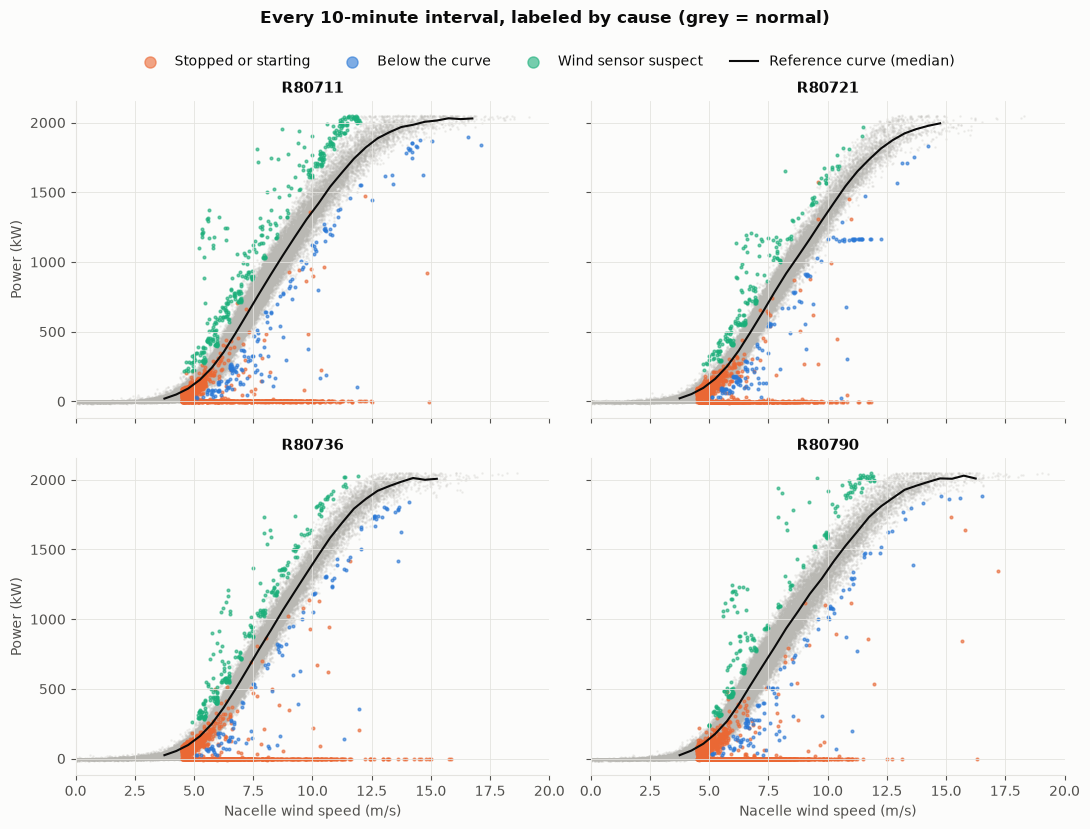

In [22]:
groups = {"Stopped or starting": (["stopped", "transition"], ORANGE),
          "Below the curve": (["derated", "underperforming"], BLUE),
          "Wind sensor suspect": (["wind sensor suspect"], AQUA)}
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True, sharey=True)
for ax, (name, g) in zip(axes.flat, lab.groupby("turbine")):
    ax.scatter(g["ws"], g["power_kw"], s=1, color=NORMAL, alpha=0.15, rasterized=True)
    for label, (labels, color) in groups.items():
        s = g[g["label"].isin(labels)]
        ax.scatter(s["ws"], s["power_kw"], s=4, color=color, alpha=0.6, label=label, rasterized=True)
    c = curve[curve["turbine"] == name]
    ax.plot(c["bin"], c["median"], color=INK, lw=1.5, label="Reference curve (median)")
    ax.set_title(name)
    ax.set_xlim(0, 20)
for ax in axes[1]:
    ax.set_xlabel("Nacelle wind speed (m/s)")
for ax in axes[:, 0]:
    ax.set_ylabel("Power (kW)")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, markerscale=4, bbox_to_anchor=(0.5, 0.99))
fig.suptitle("Every 10-minute interval, labeled by cause (grey = normal)", y=1.03, fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(f"{FIG}/power_curves_labeled.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. How robust are the labels?

The thresholds are choices, so move one and see what changes. A label that swings a lot is measuring my threshold, not the turbines.

In [23]:
sens = {f"k={k}": scada.label_points(df, curve, k=k)["label"].value_counts() for k in [2, 3, 4]}
pd.DataFrame(sens).loc[["stopped", "transition", "derated", "underperforming", "wind sensor suspect"]]

,k=2,k=3,k=4
label,,,
stopped,3229,3229,3229
transition,2852,2852,2852
derated,24,21,19
underperforming,3880,491,147
wind sensor suspect,6801,941,332


- **Labels based on what the turbine did** (stopped, transition, derated) barely move. They rest on pitch and power, physical facts that don't depend on where the line is drawn.
- **Labels based on distance from the curve** (underperforming, wind sensor suspect) swing 20-26x. Their counts mostly reflect the threshold, so I report them with the threshold stated, or as a range.

## 6. Energy lost per cause

For loss labels only: lost energy = (expected - actual) / 6, in kWh per 10-minute row. "Normal" points scatter on both sides of the curve, so counting only their shortfalls would turn noise into a fake loss. They're excluded.

In [24]:
loss = scada.loss_table(lab)
loss.round(1)

turbine,R80711,R80721,R80736,R80790,farm
label,,,,,
stopped,72.5,41.9,57.6,100.0,272.1
transition,6.2,6.4,6.5,8.3,27.5
derated,0.0,1.6,0.0,0.0,1.6
underperforming,8.6,5.2,5.8,6.9,26.5
total lost,87.3,55.2,69.9,115.2,327.7
produced,6950.5,5433.2,5945.6,6291.1,24620.4
% of potential lost,1.2,1.0,1.2,1.8,1.3


In [25]:
energy = {f"k={k}": scada.label_points(df, curve, k=k).query("label == 'underperforming'")["lost_kwh"].sum() / 1000
          for k in [2, 3, 4]}
print("underperforming, MWh:", {k: round(float(v), 1) for k, v in energy.items()})
print("stopped, MWh:", round(loss.loc["stopped", "farm"], 1))

underperforming, MWh: {'k=2': 120.0, 'k=3': 26.5, 'k=4': 12.5}
stopped, MWh: 272.1


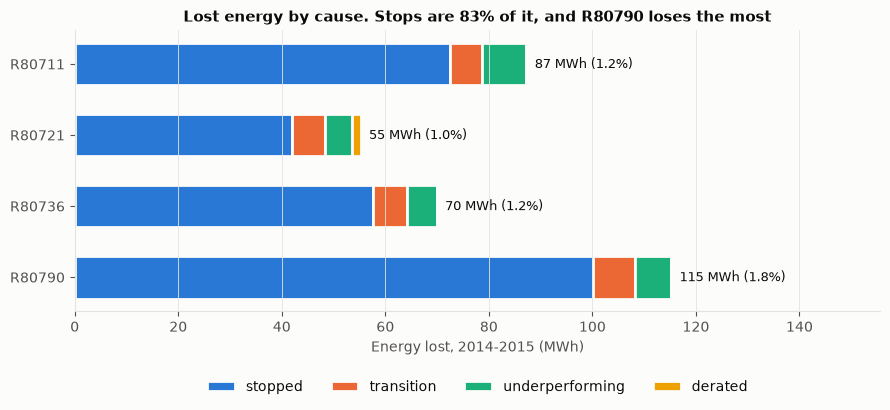

In [26]:
order = ["stopped", "transition", "underperforming", "derated"]
colors = [BLUE, ORANGE, AQUA, YELLOW]
turbines = [c for c in loss.columns if c != "farm"]
fig, ax = plt.subplots(figsize=(9, 4.3))
left = np.zeros(len(turbines))
for cause, color in zip(order, colors):
    vals = loss.loc[cause, turbines].values
    ax.barh(turbines, vals, left=left, color=color, label=cause, height=0.6,
            edgecolor=SURFACE, linewidth=2)
    left += vals
for i, tname in enumerate(turbines):
    ax.annotate(f"{loss.loc['total lost', tname]:.0f} MWh ({loss.loc['% of potential lost', tname]:.1f}%)",
                (left[i], i), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color=INK)
ax.set_xlim(0, left.max() * 1.35)
ax.invert_yaxis()
ax.set_xlabel("Energy lost, 2014-2015 (MWh)")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=4)
ax.set_title("Lost energy by cause. Stops are 83% of it, and R80790 loses the most")
fig.tight_layout()
fig.savefig(f"{FIG}/losses_by_cause.png", dpi=150)
plt.show()

- **Stops are the biggest loss by far.** The derate from case 2 made a great story, but cost only 1.6 MWh.
- **R80790 loses the most** to stops: about twice its neighbors' rate. That's the turbine to look into first.
- Even at the loosest threshold (k = 2), underperforming stays well under half of what stops cost, so "stops dominate" holds whatever threshold I pick.
- This only counts losses the SCADA can see. Wake losses, and blade icing slow enough to stay inside the band, are invisible to these rules, so the true loss is somewhat higher.

## 7. Same wind, different power: air density and stability

Power in the wind is ½ ρ A v³, so denser (colder) air should give more power at the same wind speed. I compute density from SCADA temperature and ERA5 surface pressure, and compare normal points in the densest and thinnest thirds.

In [27]:
lab = scada.add_density(lab, era5)
print(lab.groupby(lab["time"].dt.month)["rho"].mean().round(3).to_dict())

n = lab[(lab["label"] == "normal") & lab["rho"].notna()].copy()
n["band"] = pd.qcut(n["rho"], 3, labels=["thin (warm)", "middle", "dense (cold)"])
n.groupby("band", observed=True)[["rho", "temp_c"]].mean().round(3)

{1: 1.222, 2: 1.22, 3: 1.207, 4: 1.192, 5: 1.184, 6: 1.166, 7: 1.154, 8: 1.16, 9: 1.178, 10: 1.192, 11: 1.204, 12: 1.226}


,rho,temp_c
band,,
thin (warm),1.161,19.537
middle,1.194,11.486
dense (cold),1.225,5.726


**Prediction:** dense air is about 5.5% denser than thin air, so with power proportional to density it should give about 5.5% more power below rated, shrinking near rated where both hit the cap.

In [28]:
def gap(frame, col, a, b, by="band"):
    t = frame.groupby([col, by], observed=True)["power_kw"].median().unstack()
    return (100 * (t[a] / t[b] - 1)).loc[5:13]

n["bin"] = (n["ws"] // 0.5) * 0.5 + 0.25
ref_rho = n["rho"].mean()
n["ws_n"] = n["ws"] * (n["rho"] / ref_rho) ** (1 / 3)      # IEC density correction
n["bin_n"] = (n["ws_n"] // 0.5) * 0.5 + 0.25

h = n["time"].dt.hour                                        # UTC; local solar time is ~20 min ahead
n["period"] = np.select([h.between(9, 16), (h >= 20) | (h <= 4)], ["day", "night"], "dusk/dawn")

table = pd.DataFrame({
    "dense vs thin, raw (%)": gap(n, "bin", "dense (cold)", "thin (warm)"),
    "dense vs thin, density-corrected (%)": gap(n, "bin_n", "dense (cold)", "thin (warm)"),
    **{f"night vs day, {b} (%)": gap(n[n["band"] == b], "bin", "night", "day", by="period")
       for b in ["thin (warm)", "middle", "dense (cold)"]},
})
table.round(1)

,"dense vs thin, raw (%)","dense vs thin, density-corrected (%)","night vs day, thin (warm) (%)","night vs day, middle (%)","night vs day, dense (cold) (%)"
5.25,21.8,11.8,5.6,4.3,6.1
5.75,20.1,10.3,4.6,2.5,5.0
6.25,17.8,9.3,4.3,2.6,5.3
6.75,14.5,7.5,5.1,4.1,4.4
7.25,13.7,7.8,5.0,4.3,3.4
7.75,10.9,6.0,5.7,3.8,4.7
8.25,10.1,5.5,4.6,3.4,4.2
8.75,9.0,5.0,3.7,2.6,4.0
9.25,7.6,3.9,3.3,1.7,2.3
9.75,6.5,2.9,3.0,1.4,2.2


- **Density explains the gap near rated, but only about half of it at low wind.** At 5-6 m/s, cold-air turbines make about 20% more than warm-air ones, against the 5.5% that density predicts. After the IEC correction, about 10-12% is left.
- **Night beats day by about 3-6% at 5-9 m/s in every density band.** With density held fixed, that points to atmospheric stability: calm nights have more wind shear across the rotor and smoother flow, so the hub anemometer understates what the rotor sees.
- **About 5% is still unexplained.** Separating seasonal shear and turbulence from anemometer behavior would need a met mast measuring wind at several heights.

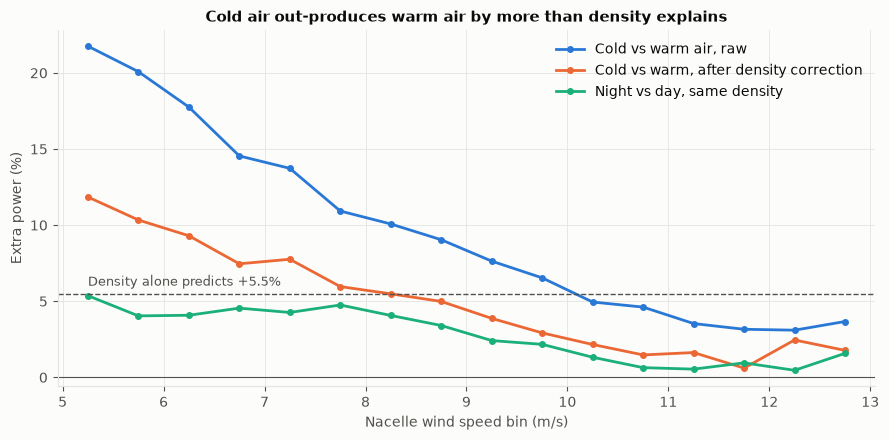

In [29]:
mid_night = table[[c for c in table.columns if c.startswith("night")]].mean(axis=1)
fig, ax = plt.subplots(figsize=(9, 4.5))
x = table.index
for series, color, label in [(table["dense vs thin, raw (%)"], BLUE, "Cold vs warm air, raw"),
                             (table["dense vs thin, density-corrected (%)"], ORANGE, "Cold vs warm, after density correction"),
                             (mid_night, AQUA, "Night vs day, same density")]:
    ax.plot(x, series, color=color, lw=2, marker="o", ms=4, label=label)
density_pred = 100 * (n.groupby("band", observed=True)["rho"].mean()["dense (cold)"]
                      / n.groupby("band", observed=True)["rho"].mean()["thin (warm)"] - 1)
ax.axhline(density_pred, color=INK2, lw=1, ls="--")
ax.annotate(f"Density alone predicts +{density_pred:.1f}%", (x[0], density_pred), xytext=(0, 6),
            textcoords="offset points", fontsize=9, color=INK2)
ax.axhline(0, color=INK2, lw=0.8)
ax.set_xlim(x[0] - 0.3, x[-1] + 0.3)
ax.set_xlabel("Nacelle wind speed bin (m/s)")
ax.set_ylabel("Extra power (%)")
ax.legend(loc="upper right")
ax.set_title("Cold air out-produces warm air by more than density explains")
fig.tight_layout()
fig.savefig(f"{FIG}/density_and_stability.png", dpi=150)
plt.show()

## Summary

| Question | Answer |
|---|---|
| Can the raw file be trusted? | No. Daylight-saving duplicates and a missing hour hidden by a perfect row count, sentinel temperatures, impossible pitch, 2,569 blank rows. All handled, and checks prove the clean version. |
| Is the clock right? | No. The logger ran on UTC but the export used Paris offsets. Shown at all four clock changes against two reanalyses, with the result predicted beforehand. |
| What causes the off-curve points? | Stops, starts, one derate, icing (anemometers and probably blades), plus a fringe of underperformance whose size depends on the threshold. |
| What did it cost? | 1.3% of potential energy; 83% of that from stops. R80790 lost 1.8%, nearly twice its neighbors. |
| Does density explain cold/warm differences? | Near rated, yes. At low wind only about half; day vs night (stability) explains part of the rest. |

In [30]:
lab.drop(columns="bin").to_parquet("scada_labeled.parquet", index=False)   # gitignored